# 第 33 课｜NumPy 矩阵运算与 PCA

本 Notebook 对应「365 天量化金融」第 33 课。课程代码主线来自本地视频、课件截图和 Whisper 口播整理；在此基础上补充量化数据语义、断言、性能验证和方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/33_youtube-8re1itSulGk/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情（**非真实股票数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **数据声明**：本 Notebook 的证券名称、价格和成交量均为教学模拟数据。它用于稳定复现计算方法，不能用于评价真实证券、市场规律或策略收益。

## 本节量化问题

课程把矩阵乘法、`linalg.solve`、协方差/相关矩阵、特征分解和 PCA 连成组合分析。本 Notebook 用第 32 课同一份**确定性模拟日线**，按下面顺序建立可核对链路：

1. 从 6 只虚构资产、756 个工作日的长表构造价格与简单收益矩阵；
2. 区分 `*` 的逐资产收益贡献与 `@` 的组合收益；
3. 从样本协方差得到组合方差，并求仅含预算约束、允许做空的全局最小方差组合；
4. 对相关矩阵做 PCA，检查第一主成分是否与这 6 只模拟资产的样本共同波动代理一致。

**输入**：`daily_prices.csv`，原始 shape 为 `(4536, 9)`。  
**核心中间结果**：价格矩阵 `(756, 6)`、收益矩阵 `(755, 6)`。  
**输出**：组合贡献表、风险与权重比较表、相关热力图、PCA 方差解释与载荷表。

这里研究的是矩阵方法，不是在验证真实市场因子，也不构成策略收益评估。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 先看原始长表

原始 CSV 中一行代表“某天、某只股票”的一组行情。`read_csv` 读取文件；`parse_dates=["date"]` 在读取时把日期文本解析为 Pandas 时间类型。

为看清“一天有多只股票”，下面展示第一个交易日的全部 6 行，而不是只看普通 `head()`。

In [2]:
# 读取原始长表，并展示首个交易日的全部股票。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
first_date = daily["date"].min()
first_day_rows = (
    daily.loc[
        daily["date"].eq(first_date),
        ["date", "symbol", "sector", "adj_close", "volume"],
    ]
    .sort_values("symbol")
    .reset_index(drop=True)
)

print("原始表 shape =", daily.shape)
print("交易日数量 =", daily["date"].nunique())
print("股票数量 =", daily["symbol"].nunique())
first_day_rows

原始表 shape = (4536, 9)
交易日数量 = 756
股票数量 = 6


,date,symbol,sector,adj_close,volume
0,2023-01-03,BANK_A,金融,11.7218,2822797
1,2023-01-03,ENERGY_A,能源,6.0296,5425851
2,2023-01-03,EV_A,新能源,27.5575,5113762
3,2023-01-03,INSURE_A,金融,41.7118,2075343
4,2023-01-03,POWER_A,公用事业,8.0817,3733504
5,2023-01-03,TECH_A,科技,36.2134,6241108


## 1. 从长表到带标签价格矩阵

`pivot` 只负责重排，不做平均或求和：

- `index="date"`：每行对应一个交易日；
- `columns="symbol"`：每列对应一只股票；
- `values="adj_close"`：格子里放复权收盘价；
- `sort_index()`：按日期标签升序排列。

`pivot` 要求每个“日期 × 股票”组合最多一行；若原始数据有重复，应先清洗，或明确使用 `pivot_table` 的聚合规则。

In [3]:
# 检查键唯一后，把复权收盘价重排为“日期 × 股票”宽表。
assert not daily.duplicated(["date", "symbol"]).any()
close = daily.pivot(
    index="date",
    columns="symbol",
    values="adj_close",
).sort_index()

assert close.index.is_unique and close.columns.is_unique
assert not close.isna().any().any()
print("close.shape =", close.shape, "含义：日期 × 股票")
close.head(3)

close.shape = (756, 6) 含义：日期 × 股票


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
date,,,,,,
2023-01-03,11.7218,6.0296,27.5575,41.7118,8.0817,36.2134
2023-01-04,11.6934,6.0138,27.5189,41.9968,8.1296,36.5943
2023-01-05,11.6864,6.0281,27.8166,41.7611,8.1630,36.0263


### 计算简单收益率

`pct_change(fill_method=None)` 对每只股票分别计算：

```text
当日简单收益率 = 当日价格 / 前一日价格 - 1
```

第一日没有前值，因此会产生一行 `NaN`。本确定性数据已确认价格矩阵没有其他缺失，所以用 `.iloc[1:]` 明确移除首行；真实多资产数据若直接 `dropna()`，任一股票缺失都可能删除整天，必须先诊断缺失原因。

In [4]:
# 按列计算相邻日简单收益，并移除必然没有前值的第一日。
returns_with_first_nan = close.pct_change(fill_method=None)
assert returns_with_first_nan.iloc[0].isna().all()
returns = returns_with_first_nan.iloc[1:]

assert not returns.isna().any().any()
print("returns.shape =", returns.shape, "含义：日期 × 股票")
returns.head(3).round(6)

returns.shape = (755, 6) 含义：日期 × 股票


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
date,,,,,,
2023-01-04,-0.002423,-0.002620,-0.001401,0.006833,0.005927,0.010518
2023-01-05,-0.000599,0.002378,0.010818,-0.005612,0.004108,-0.015522
2023-01-06,-0.003448,0.012193,0.033469,0.021439,0.001482,-0.001207


### 何时转为 NumPy

`to_numpy(dtype=np.float64)` 只保留数值，把 Pandas 的日期索引和股票列名移除。矩阵运算会更直接，但 NumPy 不再替你检查证券标签，所以转换前先保存并核验列顺序。

In [5]:
# 保存标签后转为浮点收益矩阵；R 的行是日期，列是股票。
assets = returns.columns.copy()
R = returns.to_numpy(dtype=np.float64)
T, N = R.shape

assert R.shape == (755, 6)
print("R.shape =", R.shape)
print("R.dtype =", R.dtype)
print("T（收益日期数）=", T, "N（股票数）=", N)
print("列顺序 =", assets.tolist())

R.shape = (755, 6)
R.dtype = float64
T（收益日期数）= 755 N（股票数）= 6
列顺序 = ['BANK_A', 'ENERGY_A', 'EV_A', 'INSURE_A', 'POWER_A', 'TECH_A']


## 课程示例 1：组合收益是矩阵乘法

`R` 的形状是 `(交易日, 股票)`，权重向量的形状是 `(股票,)`。

| 运算 | 做什么 | 输出 shape | 金融含义 |
|---|---|---|---|
| `R * weights` | 逐元素乘法；`(N,)` 权重沿日期维广播 | `(T, N)` | 每天、每只股票对组合收益的贡献 |
| `R @ weights` | 每行与权重向量做点积 | `(T,)` | 每天一个组合总收益 |

对某一天而言：

> 组合收益 = 股票 1 收益 × 权重 1 + 股票 2 收益 × 权重 2 + …

因此，`R @ weights` 等价于先执行 `R * weights`，再沿股票轴执行 `.sum(axis=1)`。`axis=1` 属于 `sum`，`@` 本身没有 `axis` 参数。

In [6]:
# 用 2 天 × 3 只股票的确定性数据观察 * 和 @ 的差别。
demo_returns = np.array([
    [0.01, -0.02, 0.03],   # 第 1 天三只股票收益
    [0.02,  0.01, -0.01],  # 第 2 天三只股票收益
])
demo_weights = np.array([0.50, 0.30, 0.20])

# * 逐元素相乘，保留每只股票的收益贡献，shape=(2,3)。
demo_contribution = demo_returns * demo_weights
# @ 对每一行做点积，直接得到每天组合收益，shape=(2,)。
demo_portfolio_return = demo_returns @ demo_weights

demo_table = pd.DataFrame(
    demo_contribution,
    index=["第1日", "第2日"],
    columns=["股票A贡献", "股票B贡献", "股票C贡献"],
)
demo_table["贡献合计"] = demo_contribution.sum(axis=1)
demo_table["@组合收益"] = demo_portfolio_return

np.testing.assert_allclose(demo_table["贡献合计"], demo_table["@组合收益"])
assert np.isclose(demo_portfolio_return[0], 0.005)
demo_table

,股票A贡献,股票B贡献,股票C贡献,贡献合计,@组合收益
第1日,0.005,-0.006,0.006,0.005,0.005
第2日,0.010,0.003,-0.002,0.011,0.011


第 1 天的手工计算为：

```text
1% × 50% + (-2%) × 30% + 3% × 20%
= 0.5% - 0.6% + 0.6%
= 0.5%
```

### 等权权重的形状

`np.full(N, 1 / N)` 创建长度为 `N` 的等权向量。权重必须与收益矩阵列顺序一一对应，并检查合计为 1。

In [7]:
# 创建与 assets 列顺序一致的等权权重。
weights_equal = np.full(N, 1 / N)
weight_table = pd.DataFrame(
    {"weight": weights_equal, "weight_percent": weights_equal * 100},
    index=assets,
)

assert weights_equal.shape == (N,)
assert np.isclose(weights_equal.sum(), 1)
print("weights_equal.shape =", weights_equal.shape)
print("权重合计 =", f"{weights_equal.sum():.2%}")
weight_table.round(4)

weights_equal.shape = (6,)
权重合计 = 100.00%


,weight,weight_percent
symbol,,
BANK_A,0.1667,16.6667
ENERGY_A,0.1667,16.6667
EV_A,0.1667,16.6667
INSURE_A,0.1667,16.6667
POWER_A,0.1667,16.6667
TECH_A,0.1667,16.6667


### 回到完整收益矩阵

实际数据中，`R` 有 `T` 个交易日和 `N` 只股票。下面同时保留逐股票贡献和组合总收益，并用断言验证两条计算路径一致。

In [8]:
# * 得到每天每只股票的收益贡献；@ 得到每天组合总收益。
contribution_by_asset = R * weights_equal
portfolio_return = R @ weights_equal

assert contribution_by_asset.shape == (T, N)
assert portfolio_return.shape == (T,)
np.testing.assert_allclose(
    portfolio_return,
    contribution_by_asset.sum(axis=1),
)

# 用带标签表格查看前 5 天：最后一列应等于前面各股票贡献之和。
contribution_preview = pd.DataFrame(
    contribution_by_asset[:5],
    index=returns.index[:5],
    columns=assets,
)
contribution_preview["贡献合计"] = contribution_by_asset[:5].sum(axis=1)
contribution_preview["@组合收益"] = portfolio_return[:5]
contribution_preview.round(6)

symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A,贡献合计,@组合收益
date,,,,,,,,
2023-01-04,-0.000404,-0.000437,-0.000233,0.001139,0.000988,0.001753,0.002806,0.002806
2023-01-05,-0.000100,0.000396,0.001803,-0.000935,0.000685,-0.002587,-0.000738,-0.000738
2023-01-06,-0.000575,0.002032,0.005578,0.003573,0.000247,-0.000201,0.010655,0.010655
2023-01-09,-0.002207,-0.002065,-0.002096,-0.003178,0.000355,-0.001208,-0.010399,-0.010399
2023-01-10,-0.000158,0.000697,-0.000830,-0.005278,0.000018,0.000770,-0.004780,-0.004780


这里每一期都使用同一目标权重，隐含**逐期恢复目标权重、忽略交易成本**。买入持有组合的权重会随价格漂移，不能长期直接套用固定 `weights_equal`；由收盘信号产生的权重还要滞后到可成交时点。

## 课程示例 2：协方差与相关系数

先用 3 个观测、2 个资产的确定性收益认识 API：

- `rowvar=False`：行是观测，列是资产；
- `ddof=1`：样本协方差除以 `T-1`；
- 协方差有“收益率平方”单位，相关系数没有量纲。

两者都描述样本共同波动，不等于因果关系。

In [9]:
# 用小矩阵得到可手工核对的样本协方差和相关系数。
risk_demo = np.array([
    [ 0.01,  0.00],
    [ 0.00,  0.01],
    [-0.01, -0.01],
])
demo_covariance = np.cov(risk_demo, rowvar=False, ddof=1)
demo_correlation = np.corrcoef(risk_demo, rowvar=False)

display(pd.DataFrame(
    demo_covariance,
    index=["资产A", "资产B"],
    columns=["资产A", "资产B"],
).round(5))
pd.DataFrame(
    demo_correlation,
    index=["资产A", "资产B"],
    columns=["资产A", "资产B"],
).round(2)

,资产A,资产B
资产A,0.00010,0.00005
资产B,0.00005,0.00010


,资产A,资产B
资产A,1.0,0.5
资产B,0.5,1.0


### 回到完整收益矩阵并年化

日收益样本协方差乘以 `252`，是在“约 252 个交易期、收益协方差可线性年化”的约定下得到年化协方差。它忽略自相关、交易日差异和结构变化，不是对所有过程都成立的恒等式。

In [10]:
# 估计完整样本的日协方差、相关矩阵与约定式年化协方差。
covariance = np.cov(R, rowvar=False, ddof=1)
correlation = np.corrcoef(R, rowvar=False)
annual_covariance = covariance * 252

assert covariance.shape == (N, N)
assert correlation.shape == (N, N)

# 找出对角线之外相关性最高和最低的资产对，便于核对样本结构。
upper_triangle = np.triu_indices(N, k=1)
pair_table = pd.DataFrame({
    "asset_1": assets.to_numpy()[upper_triangle[0]],
    "asset_2": assets.to_numpy()[upper_triangle[1]],
    "correlation": correlation[upper_triangle],
}).sort_values("correlation")

print("日协方差 shape =", covariance.shape)
display(pair_table.iloc[[0, -1]].reset_index(drop=True).round(4))
pd.DataFrame(correlation, index=assets, columns=assets).round(3)

日协方差 shape = (6, 6)


,asset_1,asset_2,correlation
0,BANK_A,POWER_A,0.2392
1,BANK_A,INSURE_A,0.5471


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
symbol,,,,,,
BANK_A,1.000,0.372,0.470,0.547,0.239,0.432
ENERGY_A,0.372,1.000,0.426,0.336,0.246,0.423
EV_A,0.470,0.426,1.000,0.477,0.265,0.493
INSURE_A,0.547,0.336,0.477,1.000,0.287,0.450
POWER_A,0.239,0.246,0.265,0.287,1.000,0.340
TECH_A,0.432,0.423,0.493,0.450,0.340,1.000


### 二次型得到组合方差

组合年化方差与波动率分别为：

```text
annual_variance   = wᵀ Σannual w
annual_volatility = sqrt(annual_variance)
```

方差的单位是收益率平方，不应把它直接当作普通百分比；开平方后才是与收益率同量纲的波动率。

In [11]:
# 用二次型计算等权组合年化方差，再开平方得到年化波动率。
equal_variance = weights_equal @ annual_covariance @ weights_equal
equal_volatility = np.sqrt(equal_variance)

risk_summary = pd.Series({
    "年化方差（收益率平方）": equal_variance,
    "年化波动率": equal_volatility,
}, name="等权组合")
display(risk_summary.to_frame())
print("等权组合年化波动率 =", f"{equal_volatility:.4%}")

,等权组合
年化方差（收益率平方）,0.017862
年化波动率,0.133647


等权组合年化波动率 = 13.3647%


## 课程示例 3：`np.linalg.solve` 与最小方差权重

先用固定方程 `A @ x = b` 认识 `solve`。它直接求解线性方程，不显式构造逆矩阵，通常比 `np.linalg.inv(A) @ b` 更稳定。

In [12]:
# 解固定的 2 × 2 线性方程，并代回验证。
A = np.array([[2.0, 1.0], [1.0, 3.0]])
b = np.array([1.0, 1.0])
x = np.linalg.solve(A, b)

np.testing.assert_allclose(A @ x, b)
pd.DataFrame({"x": x, "A @ x": A @ x, "b": b}, index=["方程1", "方程2"])

,x,A @ x,b
方程1,0.4,1.0,1.0
方程2,0.2,1.0,1.0


### 仅含预算约束、允许做空的全局最小方差组合

只要求权重和为 1 时，全局最小方差（Global Minimum Variance, GMV）权重为：

```text
w = Σ⁻¹1 / (1ᵀΣ⁻¹1)
```

`np.linalg.solve(Σ, 1)` 直接求解 `Σx=1`。这里仍有“权重合计为 1”的预算约束，但没有多头或仓位上下限，所以负权重表示做空。

In [13]:
# 求仅含预算约束的 GMV 方向，再归一化使权重和为 1。
ones = np.ones(N)
raw_solution = np.linalg.solve(annual_covariance, ones)
budget_only_gmv = raw_solution / (ones @ raw_solution)
gmv_variance = budget_only_gmv @ annual_covariance @ budget_only_gmv
gmv_volatility = np.sqrt(gmv_variance)

assert np.isclose(budget_only_gmv.sum(), 1)
assert gmv_variance <= equal_variance + 1e-12
weight_comparison = pd.DataFrame(
    {
        "等权": weights_equal,
        "预算约束_GMV_允许做空": budget_only_gmv,
    },
    index=assets,
)
weight_percent_table = (weight_comparison * 100).rename(
    columns=lambda name: f"{name}（%）"
)
display(weight_percent_table.round(4).rename_axis("股票"))
pd.DataFrame(
    {
        "年化方差": [equal_variance, gmv_variance],
        "年化波动率": [equal_volatility, gmv_volatility],
    },
    index=["等权", "预算约束_GMV_允许做空"],
)

,等权（%）,预算约束_GMV_允许做空（%）
股票,,
BANK_A,16.6667,19.3490
ENERGY_A,16.6667,20.9145
EV_A,16.6667,-1.2637
INSURE_A,16.6667,11.3898
POWER_A,16.6667,51.8114
TECH_A,16.6667,-2.2010


,年化方差,年化波动率
等权,0.017862,0.133647
预算约束_GMV_允许做空,0.012824,0.113242


GMV 结果只是在同一训练样本内优化和评价：协方差矩阵奇异或病态时 `solve` 会失败或极不稳定；本例也没有多头、仓位上限、换手、成本或样本外验证，不能直接当作可执行组合。

### 相关矩阵热力图怎么读？

- 每个格子是两只股票日收益的相关系数，范围为 `-1～1`；
- 对角线是资产与自身的相关性，恒为 `1.00`；
- 红色表示正相关，蓝色表示负相关，接近白色表示线性相关较弱；
- 图中直接标出两位小数，颜色用于快速浏览，数字用于准确比较。

热力图里的红色只是“正相关”的颜色编码，**不是 Notebook 告警**。相关性描述样本期内的同步波动，不代表因果关系，也不保证未来稳定。

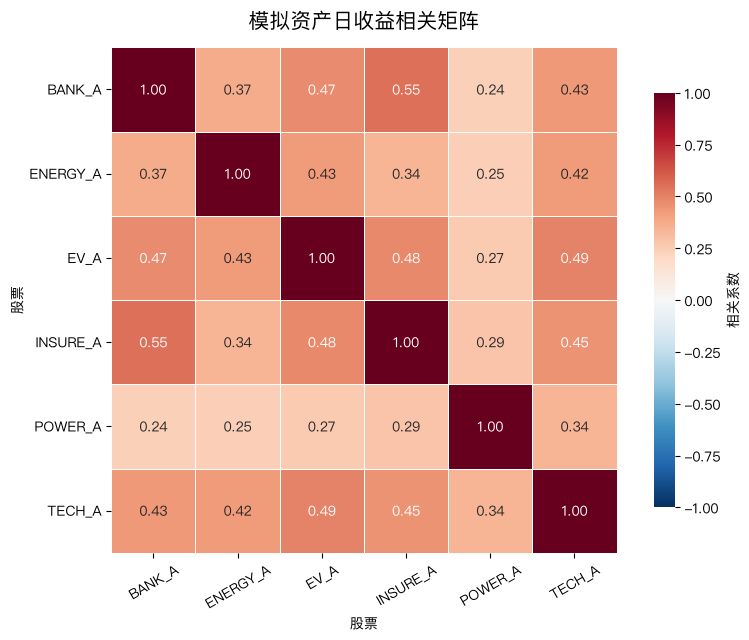

In [14]:
# 用带数值标注的热力图同时呈现相关方向、强弱和精确数值。
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(
    correlation,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.6,
    linecolor="white",
    xticklabels=assets,
    yticklabels=assets,
    annot_kws={"fontsize": 10},
    cbar_kws={"label": "相关系数", "shrink": 0.82},
)
ax.set_title("模拟资产日收益相关矩阵", fontsize=15, pad=14)
ax.set_xlabel("股票")
ax.set_ylabel("股票")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "33_correlation_matrix.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 课程示例 4：特征分解与 PCA

PCA（Principal Component Analysis，主成分分析）把多个相关资产压缩为少数互不相关的统计方向。第一步先把每只股票收益标准化：

```text
标准化收益 = (原收益 − 样本均值) / 样本标准差
```

这样高波动股票不会仅因为数值尺度更大而主导结果。`axis=0` 表示每只股票沿时间维分别计算均值；`ddof=1` 与样本协方差口径一致。标准化后每列均值约为 0、样本标准差约为 1，因此下面等价于对收益相关矩阵做 PCA，而不是对原始协方差矩阵做 PCA。

In [15]:
# 对每只股票沿时间轴标准化，并检查列均值与标准差。
standardized = (R - R.mean(axis=0)) / R.std(axis=0, ddof=1)
standardized_table = pd.DataFrame(
    standardized,
    index=returns.index,
    columns=assets,
)
standardization_check = pd.DataFrame(
    {
        "mean": standardized_table.mean(),
        "std_ddof1": standardized_table.std(ddof=1),
    }
)
standardization_check.round(6)

,mean,std_ddof1
symbol,,
BANK_A,-0.0,1.0
ENERGY_A,-0.0,1.0
EV_A,-0.0,1.0
INSURE_A,-0.0,1.0
POWER_A,0.0,1.0
TECH_A,0.0,1.0


### 特征值、特征向量与解释率

先用一个固定对称矩阵认识 `np.linalg.eigh`：

- 它用于实对称或复 Hermitian 矩阵；
- 特征值默认升序；
- 特征向量按列存放；
- 特征向量整体乘以 `-1` 仍表示同一方向。

In [16]:
# 分解固定对称矩阵，并用 V @ diag(λ) @ V.T 重建原矩阵。
symmetric_demo = np.array([[2.0, 1.0], [1.0, 2.0]])
demo_eigenvalues, demo_eigenvectors = np.linalg.eigh(symmetric_demo)
demo_reconstructed = (
    demo_eigenvectors
    @ np.diag(demo_eigenvalues)
    @ demo_eigenvectors.T
)

np.testing.assert_allclose(demo_reconstructed, symmetric_demo)
print("特征值（默认升序）=", demo_eigenvalues)
print("重建矩阵：\n", np.round(demo_reconstructed, 6))

特征值（默认升序）= [1. 3.]
重建矩阵：
 [[2. 1.]
 [1. 2.]]


### 实际 PCA 与方差解释比例

特征值表示每个主成分解释的样本方差；特征向量表示该统计方向对各股票的载荷。实际使用时按特征值倒序排列。方差解释比例是“该特征值 ÷ 全部特征值之和”，累计比例最终应为 100%。

In [17]:
# 对标准化收益的相关矩阵做特征分解，并按解释方差从大到小排序。
corr_for_pca = np.cov(standardized, rowvar=False, ddof=1)
eigenvalues, eigenvectors = np.linalg.eigh(corr_for_pca)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained_ratio = eigenvalues / eigenvalues.sum()

assert np.isclose(explained_ratio.sum(), 1)
pca_summary = pd.DataFrame(
    {
        "特征值": eigenvalues,
        "方差解释比例": [f"{value:.3%}" for value in explained_ratio],
        "累计比例": [f"{value:.3%}" for value in np.cumsum(explained_ratio)],
    },
    index=[f"PC{i}" for i in range(1, N + 1)],
)
pca_summary.round(4)

,特征值,方差解释比例,累计比例
PC1,2.9691,49.484%,49.484%
PC2,0.8287,13.812%,63.296%
PC3,0.7107,11.845%,75.141%
PC4,0.5527,9.211%,84.353%
PC5,0.4941,8.235%,92.588%
PC6,0.4447,7.412%,100.000%


### 第一主成分载荷、得分与共同波动代理

- `eigenvectors[:, 0]`：PC1 对每只股票的载荷；
- `standardized @ loading`：每个日期的 PC1 得分；
- `standardized.mean(axis=1)`：这 6 只样本资产的等权标准化共同波动代理，不是可交易市场组合收益。

为让不同线性代数实现的展示方向一致，下面约定“绝对值最大的载荷为正”；这只是符号规范，不改变主成分本身。

In [18]:
# 统一 PC1 符号，计算得分，并与样本共同波动代理比较。
pc1_loading = eigenvectors[:, 0].copy()
largest_loading_position = np.argmax(np.abs(pc1_loading))
if pc1_loading[largest_loading_position] < 0:
    pc1_loading *= -1

first_pc_score = standardized @ pc1_loading
equal_weight_proxy = standardized.mean(axis=1)
pc_proxy_corr = np.corrcoef(first_pc_score, equal_weight_proxy)[0, 1]

loading_table = pd.DataFrame(
    {"PC1载荷": pc1_loading},
    index=assets,
)
display(loading_table.round(4))
print("PC1 与样本共同波动代理相关系数 =", round(float(pc_proxy_corr), 3))
assert pc_proxy_corr > 0.5

,PC1载荷
symbol,
BANK_A,0.4314
ENERGY_A,0.3832
EV_A,0.4415
INSURE_A,0.4360
POWER_A,0.2990
TECH_A,0.4388


PC1 与样本共同波动代理相关系数 = 0.998


## 可复用结论、练习与边界

### 可复用结论

1. Pandas 负责对齐日期和股票标签，NumPy 负责形状明确后的矩阵运算。
2. `*` 保留逐资产贡献，`@` 收缩资产维得到组合总收益。
3. `wᵀΣw` 是组合方差，开平方才是波动率。
4. PCA 最大化样本方差解释量，不最大化收益，也不自动提供预测信号。

### 建议练习

- 把等权改成自定义权重，先检查 shape、列顺序和权重合计，再核对“贡献合计 = `@` 结果”。
- 删除一只股票后重新计算 GMV 与 PCA，观察协方差估计和 PC1 载荷如何变化。
- 把样本拆为训练期和测试期，只在训练期估计协方差/PCA，再检查测试期稳定性。

### 方法边界

- `np.linalg.eigh` 针对对称矩阵，返回特征值默认从小到大，第一主成分要倒序取。
- 特征向量整体乘以 `-1` 仍是同一方向，因此符号没有固定含义。
- 预算约束 GMV 允许产生负权重；它不是 A 股普通多头账户可直接执行的组合。
- 样本内最小方差通常偏乐观，协方差和主成分会随窗口变化。
- 全样本 PCA 只适合描述；若用作预测特征，必须在训练窗口拟合，避免未来信息。
- PC1 与本样本代理高度相关，只说明模拟样本同步，不证明它是真实市场因子。